# 02 -- Price elasticity (own and cross)

Model (per brand x pack, store-week level, `beverage_demand.elasticity`):

`ln(units) = b_own ln(own price) + sum b_j ln(competitor j price) + promo-type dummies
+ post-promo dummies + holiday dummies + Fourier seasonality + year effects + store fixed effects`

Standard errors are clustered by store. See `docs/methodology.md` for why each piece is there.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

In [2]:
own = pd.read_csv(results("elasticities.csv"))
own[["series", "own_elasticity", "ci_low", "ci_high", "n_obs", "n_stores", "r2"]]

,series,own_elasticity,ci_low,ci_high,n_obs,n_stores,r2
0,Pepsi | 24pk can,-6.209,-6.377,-6.041,28902,86,0.711
1,Diet Pepsi | 24pk can,-5.710,-5.833,-5.587,28977,86,0.723
2,Diet Coke | 24pk can,-5.642,-5.867,-5.417,28045,86,0.726
3,Coke | 24pk can,-5.518,-5.671,-5.364,28523,86,0.738
4,7Up | 24pk can,-5.021,-5.159,-4.882,27502,86,0.698
5,Private Label | 24pk can,-4.628,-4.834,-4.421,16957,80,0.596
6,Pepsi | 2L,-4.041,-4.130,-3.951,31495,86,0.800
7,Diet Pepsi | 2L,-3.890,-3.978,-3.802,31493,86,0.781
8,Coke | 2L,-3.491,-3.642,-3.340,31407,86,0.792
9,Diet Coke | 2L,-3.325,-3.440,-3.211,31399,86,0.829


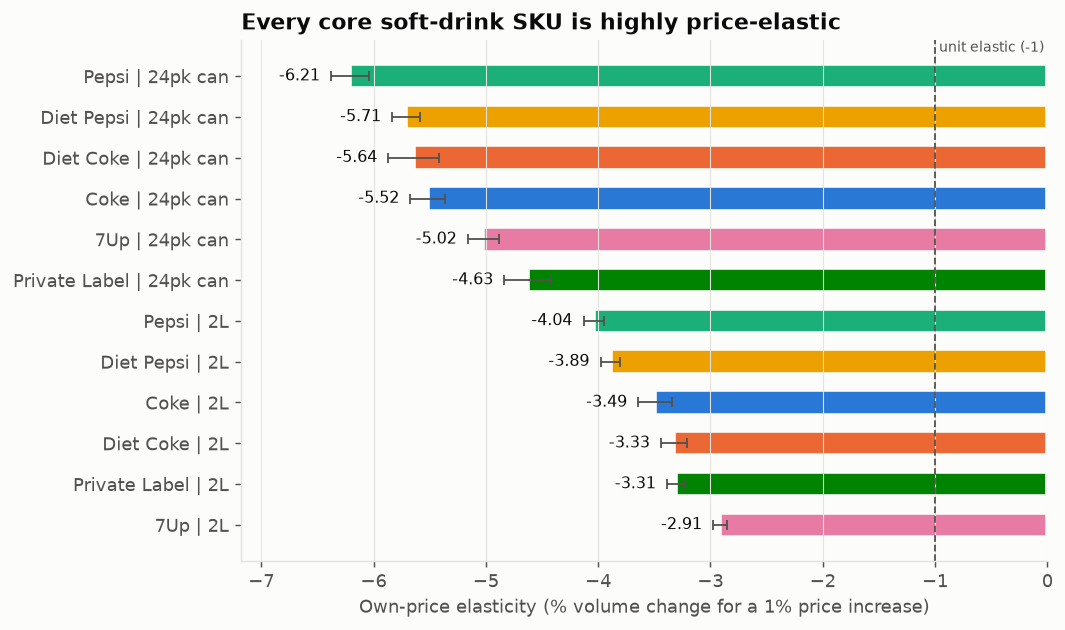

In [3]:
Image(filename=str(figure("elasticity_own.png")))

In [4]:
for t in own.sort_values("own_elasticity")["interpretation"]:
    print("-", t)

- A 1% price increase on Pepsi | 24pk can reduces its volume by about 6.2% (95% CI -6.38 to -6.04); a 10% cut lifts volume by ~92%.
- A 1% price increase on Diet Pepsi | 24pk can reduces its volume by about 5.7% (95% CI -5.83 to -5.59); a 10% cut lifts volume by ~83%.
- A 1% price increase on Diet Coke | 24pk can reduces its volume by about 5.6% (95% CI -5.87 to -5.42); a 10% cut lifts volume by ~81%.
- A 1% price increase on Coke | 24pk can reduces its volume by about 5.5% (95% CI -5.67 to -5.36); a 10% cut lifts volume by ~79%.
- A 1% price increase on 7Up | 24pk can reduces its volume by about 5.0% (95% CI -5.16 to -4.88); a 10% cut lifts volume by ~70%.
- A 1% price increase on Private Label | 24pk can reduces its volume by about 4.6% (95% CI -4.83 to -4.42); a 10% cut lifts volume by ~63%.
- A 1% price increase on Pepsi | 2L reduces its volume by about 4.0% (95% CI -4.13 to -3.95); a 10% cut lifts volume by ~53%.
- A 1% price increase on Diet Pepsi | 2L reduces its volume by about

**So what:** Every core SKU is strongly price-elastic (all own-price elasticities are negative and
well below -1). 24-pack cans (-4.6 to -6.2) react much more than 2-litre bottles (-2.9 to -4.0):
cans are a planned, stock-up purchase, so shoppers time their buying to the price.

## Cross-price elasticities

In [5]:
cross = pd.read_csv(results("cross_elasticities.csv"))
cross.pivot_table(index=["pack", "focal_brand"], columns="competitor_brand", values="cross_elasticity").round(2)

competitor_brand         7Up  Coke  Diet Coke  Pepsi  Private Label
pack     focal_brand                                               
24pk can 7Up             NaN  0.61      -0.10   0.21           0.05
         Coke           0.18   NaN        NaN   0.37           0.04
         Diet Coke      0.37   NaN        NaN   0.55           0.09
         Diet Pepsi     0.39  1.00      -0.17    NaN           0.07
         Pepsi          0.42  1.00      -0.15    NaN           0.06
         Private Label  0.13  0.22        NaN  -0.54            NaN
2L       7Up             NaN  0.20      -0.02  -0.25           0.04
         Coke           0.05   NaN      -0.27   0.32           0.19
         Diet Coke      0.11 -0.06        NaN   0.34           0.18
         Diet Pepsi     0.09  0.27       0.17    NaN           0.21
         Pepsi          0.12  0.28       0.02    NaN           0.22
         Private Label  0.24  0.29      -0.03   0.27            NaN

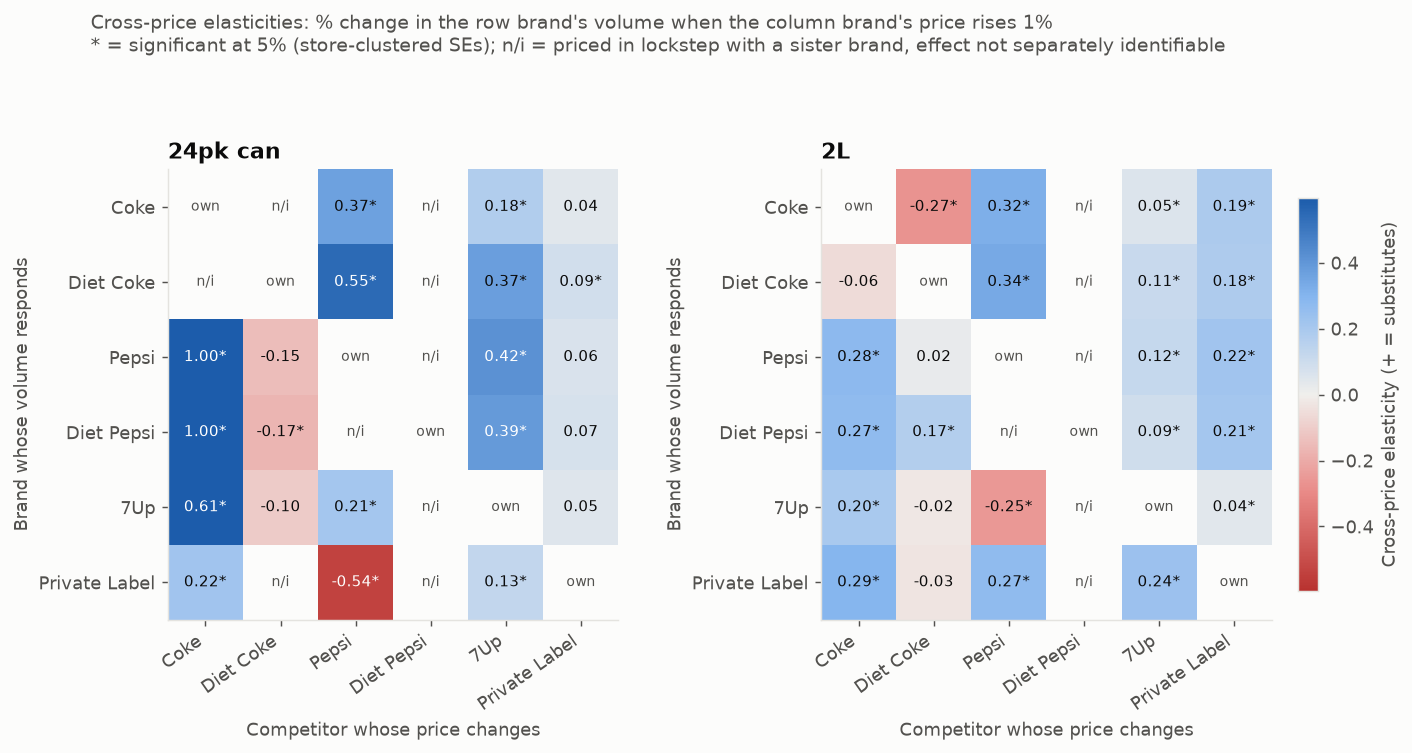

In [6]:
Image(filename=str(figure("elasticity_cross_heatmap.png")))

In [7]:
cross.loc[~cross["identified"], ["series", "competitor_brand", "note"]]

,series,competitor_brand,note
2,7Up | 24pk can,Diet Pepsi,not identified separately: priced in lockstep ...
6,Coke | 24pk can,Diet Coke,not identified: priced in lockstep with the fo...
7,Coke | 24pk can,Diet Pepsi,not identified separately: priced in lockstep ...
11,Diet Coke | 24pk can,Coke,not identified: priced in lockstep with the fo...
12,Diet Coke | 24pk can,Diet Pepsi,not identified separately: priced in lockstep ...
18,Diet Pepsi | 24pk can,Pepsi,not identified: priced in lockstep with the fo...
23,Pepsi | 24pk can,Diet Pepsi,not identified: priced in lockstep with the fo...
27,Private Label | 24pk can,Diet Coke,not identified separately: priced in lockstep ...
28,Private Label | 24pk can,Diet Pepsi,not identified separately: priced in lockstep ...
32,7Up | 2L,Diet Pepsi,not identified separately: priced in lockstep ...


**So what:** Most identifiable cross-elasticities are positive (brands are substitutes): when Coke
24-packs get more expensive, Pepsi and Diet Pepsi 24-packs gain volume. Some sister brands
(Pepsi / Diet Pepsi, and Coke / Diet Coke in 24-packs) are always priced together, so the data
cannot separate their effects -- the table marks those pairs instead of reporting a misleading
number. A few negative values (e.g. private-label 24-packs vs. Pepsi) are most likely joint
chain-wide promotional events rather than true complementarity; treat them with caution.

## Promotion effects, post-promotion dip, robustness

In [8]:
eff = pd.read_csv(results("promo_effects.csv"))
eff.pivot_table(index="series", columns="term", values="coef_pct").round(3)

term,post_promo_1,post_promo_2,promo_b,promo_c,promo_g,promo_s,promo_u
series,,,,,,,
7Up | 24pk can,-0.154,-0.123,1.985,NaN,NaN,1.659,0.133
7Up | 2L,-0.011,-0.028,0.024,NaN,-0.083,0.069,0.018
Coke | 24pk can,-0.122,-0.119,0.893,NaN,NaN,1.035,-0.038
Coke | 2L,-0.008,0.080,0.057,0.101,NaN,0.075,-0.058
Diet Coke | 24pk can,-0.176,-0.126,1.032,NaN,NaN,0.975,0.076
Diet Coke | 2L,-0.074,-0.018,0.032,-0.114,NaN,0.094,-0.025
Diet Pepsi | 24pk can,-0.087,-0.081,1.115,NaN,NaN,1.186,-0.057
Diet Pepsi | 2L,0.005,-0.016,0.106,-0.061,NaN,0.144,-0.050
Pepsi | 24pk can,-0.165,-0.110,0.910,NaN,NaN,0.910,-0.211


Promo-type coefficients are the volume effect *on top of* the price cut (display/feature support).
`post_promo_1/2` measure the dip after a promotion ends (pantry loading).

In [9]:
pd.read_csv(results("elasticity_robustness.csv")).round(2)

,series,baseline,pooled,tier_High,tier_Low,tier_Medium
0,Pepsi | 24pk can,-6.21,-6.24,-6.35,-6.29,-6.13
1,Diet Pepsi | 24pk can,-5.71,-5.85,-5.67,-5.69,-5.73
2,Diet Coke | 24pk can,-5.64,-5.69,-5.48,-5.57,-5.73
3,Coke | 24pk can,-5.52,-5.94,-5.52,-5.61,-5.50
4,7Up | 24pk can,-5.02,-5.68,-5.03,-5.33,-4.99
5,Private Label | 24pk can,-4.63,-4.78,-4.40,-5.03,-4.66
6,Pepsi | 2L,-4.04,-2.95,-3.92,-4.15,-4.08
7,Diet Pepsi | 2L,-3.89,-2.73,-3.65,-4.10,-3.98
8,Coke | 2L,-3.49,-2.75,-3.39,-3.57,-3.54
9,Diet Coke | 2L,-3.33,-2.27,-3.15,-3.44,-3.41


**So what:** The estimates are stable: a pooled model with shared controls and a model that lets
elasticity differ by store price tier give the same picture (see `results/summary.json` for the
correlation and the largest tier deviation). The main caveat is **endogeneity** -- the retailer
chooses when to cut prices -- discussed in `docs/methodology.md`.